Ce notebook presente un modele de Deep learning avec tranfert Learning pour la variable cible 'TousAge_allergie_urgences'

On va partir du modèle TabPFN

C'est un modèle de type Transformer qui a été pré-entraîné par des chercheurs sur des millions de jeux de données tabulaires synthétiques.

Le principe : Contrairement à un modèle classique qu'on entraîne de zéro, TabPFN est déjà entraîné. Tu lui donnes directement ton jeu de données tabulaire et ta cible, et il fait la prédiction en mode zero-shot, sans phase d'entraînement longue.

Il gère très bien les petits et moyens jeux de données tabulaires.

Il surpasse souvent les forêts aléatoires (Random Forest) ou XGBoost sans nécessiter des heures de réglage d'hyperparamètres (hyperparameter tuning).

Il s'installe très facilement en Python

In [69]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../content/sample_data/Merge_final_2.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  object 
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5     

/tmp/ipykernel_1498/1598684735.py:4: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../content/sample_data/Merge_final_2.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [70]:
#Suppression colonnes
Merge_final_FS_MLA = Merge_final.drop(columns=[
    '0an_bronchiolite_urgences',
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  object 
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5     

In [71]:
#Met dans le bon type les variables

Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  object 
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5     

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


Étape 1 : Préparation du DataFrame & Découpage Temporel

In [72]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  object 
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5     

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,14.357143,42.928571,8.000000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,16.242857,22.714286,30.785714,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,16.784615,34.928571,16.727273,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,21.714286,29.071429,15.250000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,18.478571,35.500000,19.142857,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [73]:
# Extraction du numéro de semaine
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)

# Tri indispensable par département et ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])

# Cible : la semaine future que l'on souhaite prédire (t+1)
df['target_futur'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(-1)

# Features basées strictement sur le passé (t-1 et t-2)
# La semaine juste avant (t-1)
df['lag_1_semaine_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Il y a 2 semaines (t-2)
df['lag_2_semaines_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(2)

# Moyenne des 2 semaines d'avant
df['moyenne_passe_2w'] = (df['lag_1_semaine_avant'] + df['TousAge_allergie_urgences']) / 2

# Nettoyage global de toutes les variables de lag et de la cible pour éviter les NaN
df = df.dropna(subset=['lag_1_semaine_avant', 'lag_2_semaines_avant', 'target_futur'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')

Train : (9792, 62) | Val : (4992, 62) | Test : (4896, 62)


Étape 3 : Preprocessing pour Deep learning

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee', 'target_futur']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['target_futur']

X_val = df_val.drop(columns=cols_to_drop)
y_val = df_val['target_futur']

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['target_futur']

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'Colonnes numériques ({len(num_cols)}) : {num_cols}')
print(f'Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}')

# Construction du préprocesseur pour le DNN
preprocessor_pfn= ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
        remainder='passthrough'
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_pfn = preprocessor_pfn.fit_transform(X_train)
X_val_pfn = preprocessor_pfn.transform(X_val)
X_test_pfn = preprocessor_pfn.transform(X_test)

print('\nDimensions après preprocessing KNN :')
print(f'X_train_pfn : {X_train_pfn.shape}')
print(f'X_val_pfn   : {X_val_pfn.shape}')
print(f'X_test_pfn  : {X_test_pfn.shape}')

Colonnes numériques (57) : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_genera

Étape 5 : tabPFN

In [75]:
!pip install tabpfn

In [76]:
from tabpfn import TabPFNRegressor
import os

os.environ["TABPFN_TOKEN"] = "tabpfn_sk_g7wqWmjHJeTCqNCwoaKYQs3MGQcGL_3njCz4-vM8I3E"

# Initialisation du modèle pré-entraîné
model = TabPFNRegressor(device='cuda')

# Fit rapide (un passage en mémoire pour l'inférence zero-shot)
model.fit(X_train_pfn, y_train)


TabPFNRegressor(device='cuda')

In [77]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Génération des prédictions sur les différents jeux
y_pred_train = model.predict(X_train_pfn).flatten()
y_pred_val = model.predict(X_val_pfn).flatten()
y_pred_test = model.predict(X_test_pfn).flatten()

# Fonction pour afficher les scores
def evaluate_regression(y_true, y_pred, dataset_name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    print(f"--- Performances TabPFN sur le jeu de {dataset_name} ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : {mae:.4f}")
    print(f"RMSE     : {rmse:.4f}\n")

# Évaluation
evaluate_regression(y_train, y_pred_train, "Train")
evaluate_regression(y_val, y_pred_val, "Validation")
evaluate_regression(y_test, y_pred_test, "Test Final")

--- Performances TabPFN sur le jeu de Train ---
R² Score : 0.8695
MAE      : 81.0548
RMSE     : 116.4467

--- Performances TabPFN sur le jeu de Validation ---
R² Score : 0.4679
MAE      : 171.0734
RMSE     : 235.9583

--- Performances TabPFN sur le jeu de Test Final ---
R² Score : 0.4256
MAE      : 162.4584
RMSE     : 222.7265



Graphique de parité (Valeurs Réelles vs Prédites)

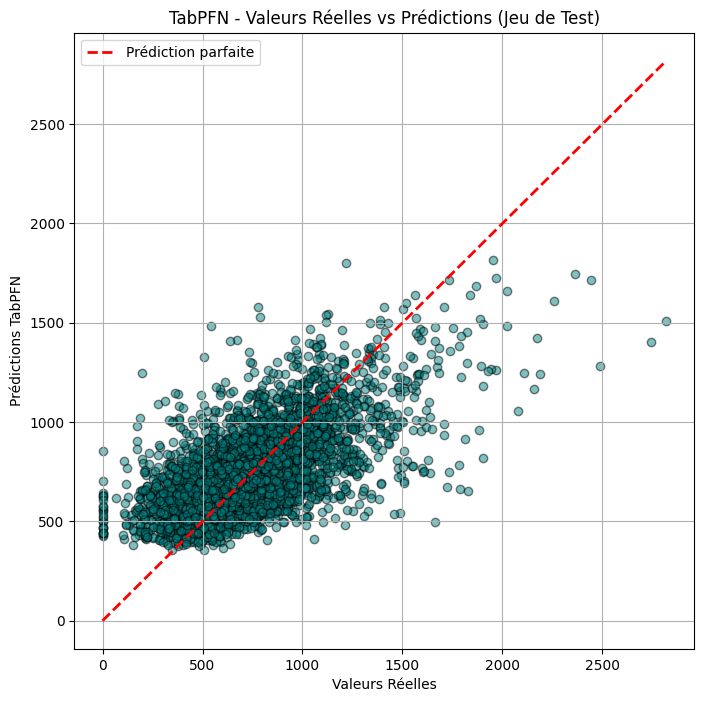

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_test, alpha=0.5, color='teal', edgecolors='k')

# Ligne diagonale parfaite (y_pred = y_true)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="Prédiction parfaite")

plt.xlabel("Valeurs Réelles")
plt.ylabel("Prédictions TabPFN")
plt.title("TabPFN - Valeurs Réelles vs Prédictions (Jeu de Test)")
plt.legend()
plt.grid(True)
plt.show()

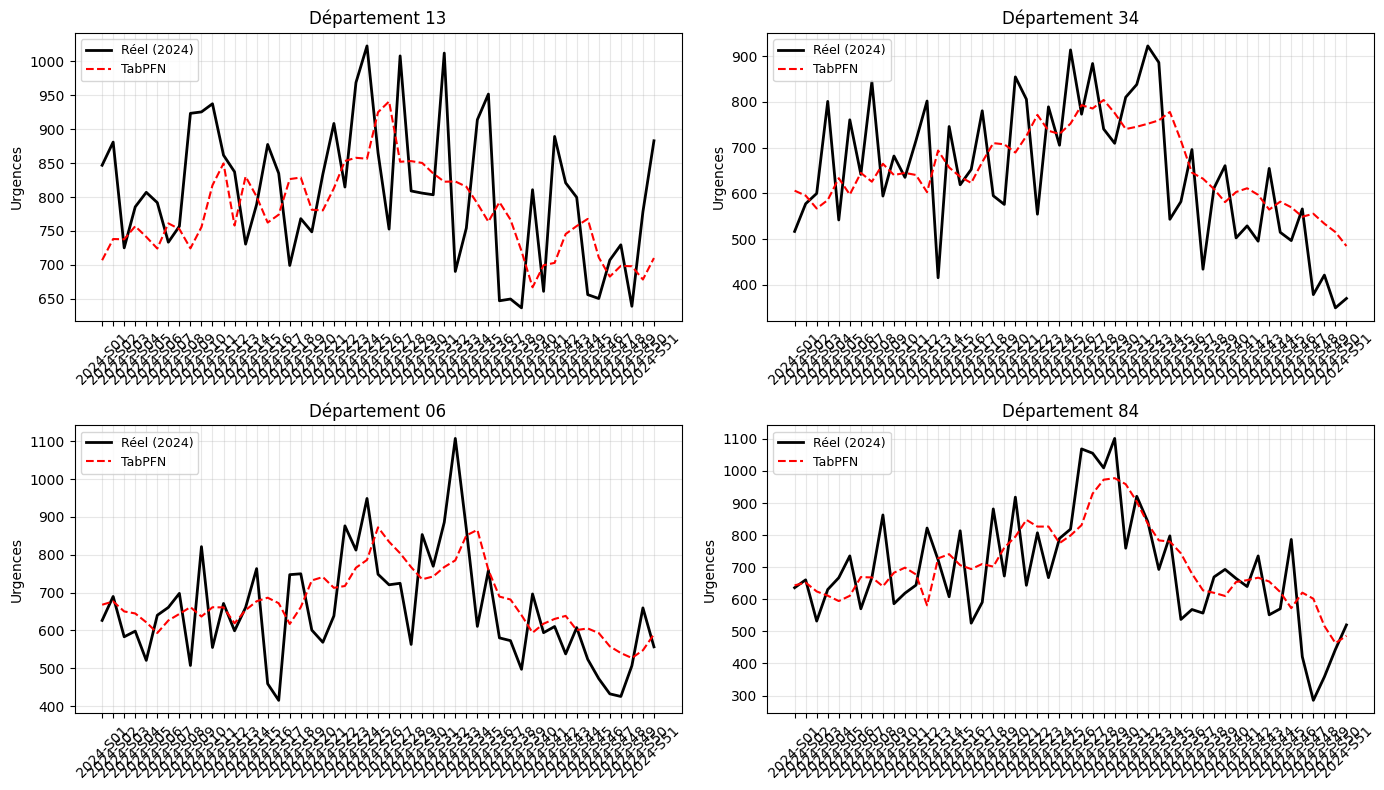

In [79]:
# Ajout des prédictions TabPFN
df_test_viz = df_test.copy()
df_test_viz['pred_tabpfn'] = y_pred_test # Remplacement du nom

# tri temporel obligatoires pour un plot propre
df_test_viz = df_test_viz.sort_values(by=['code_dept', 'date_semaine'])

# Sélection des départements
depts_cibles = ['13', '34', '06', '84']

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=False)
axes = axes.flatten()

for i, dept in enumerate(depts_cibles):
    ax = axes[i]
    sub_df = df_test_viz[df_test_viz['code_dept'] == dept]

    ax.plot(
        sub_df['date_semaine'],
        sub_df['target_futur'],
        label='Réel (2024)',
        color='black',
        linewidth=2,
    )
    ax.plot(
        sub_df['date_semaine'],
        sub_df['pred_tabpfn'],
        label='TabPFN',
        color='red',
        linestyle='--',
        linewidth=1.5,
    )

    ax.set_title(f'Département {dept}')
    ax.set_ylabel('Urgences')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Permutation importance

In [80]:
from sklearn.inspection import permutation_importance

# Calcul de la permutation importance
result = permutation_importance(
    model, X_test_pfn, y_test,
    n_repeats=5,
    random_state=42,
    scoring='r2'  # On mesure la baisse du R²
)

# Organisation des résultats dans un DataFrame pour trier
importances_df = pd.DataFrame({
    'Feature': X_test_pfn.columns,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=True)  # Tri croissant pour l'affichage horizontal

# 3. Visualisation graphique
plt.figure(figsize=(10, 6))
plt.barh(importances_df['Feature'], importances_df['Importance_Mean'], xerr=importances_df['Importance_Std'], color='teal', align='center', alpha=0.8)
plt.xlabel("Baisse du score R² (plus c'est haut, plus la variable est importante)")
plt.title("Importance des variables (Permutation Importance - TabPFN)")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

In [81]:
top_features = importances_df.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features['feature'][::-1], top_features['importance_mean'][::-1], color='darkorange')
plt.title("Importance des features par Permutation (DNN Régression - Impact sur la RMSE)")
plt.xlabel("Baisse du score (Impact négatif sur la performance en cas de permutation)")
plt.tight_layout()
plt.show()

NameError: name 'importances_df' is not defined